<a href="https://colab.research.google.com/github/rhemamfrancis/virtual-screening-smina-docking/blob/main/Virtual_screening_workflow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Virtual Screening Workflow
## Rhema Francis
## 10.07.2026

### 1. Introduction


 Anaplastic lymphoma kinase (ALK) is a membrane-bound tyrosine kinase receptor that belongs to the insulin receptor family. Under normal conditions, ALK is mainly expressed in the developing central and peripheral nervous systems. It's activated by two secreted ligands, ALKAL1 and ALKAL2, and helps support the the proliferation, survival, and differentiation of immature nerve cells (Katic & Priscan, 2023). ALK expression decreases significantly after birth, and mice without the ALK gene have been reported to survive well with only small changes in behavior and energy metabolism (Dedoni et al., 2023). This suggests that ALK is more important during early development than in adulthood, which makes it a promising drug target because blocking its activity may have fewer effects on healthy adult tissues.

 The ALK pathway is intiated by ligand (ALKAL1/2) binding or oncogenic fusion/mutation of the kinase domain. Once ALK is activated, phosphate groups are added to specific sites, including Y1278, Y1282, and Y1283 (Katic & Priscan, 2023). This allows proteins such as SHC, GRB2, and IRS1 to activate signaling pathways like RAS-MAPK/ERK, PI3K-AKT-mTOR, JAK-STAT3, and PLCγ. These pathways send signals that help cells grow, divide, and survive. Hyperactivation of these signaling pathways can cause uncontrolled cell growth and lead to ALK-positive cancers, including non-small cell lung cancer (NSCLC), anaplastic large cell lymphoma (ALCL), and neuroblastoma.

 Since ALK uses ATP to activate signaling pathways that promote cell proliferation, blocking ATP from binding can stop these signals. This makes the ATP-binding pocket an important target for drug development (Umapathy et al., 2019). By screening compounds that can bind to this pocket, researchers can identify potential ALK inhibitors that may help prevent uncontrolled cell growth in ALK-positive cancers (Umapathy et al., 2019).

 According to UniProt (n.d.), 79 PDB entries are listed for ALK (Q9UM73): 72 X-ray, 2 cryo-EM and 5 NMR structures. 64 of the X-ray entries cover the intracellular kinase domain (residues 1058-1411) and are relevant to the ATP-binding site. The others cover the extracellular region (648–1030), a small section of the activation loop (1274–1283), or the C-terminal region (1571–1589). Table 1 shows the 11 kinase-domain structures with the best resolution (1.55-1.70 Å).

**Table 1.** Top 11 ALK kinase-domain structures with the highest resolution reported in UniProt (Q9UM73).
| PDB ID | Method | Resolution (Å) | Chain(s) | Residues |
|---|---|---|---|---|
| 4Z55 | X-ray | 1.55 | A | 1072-1410 |
| 9GBE | X-ray | 1.58 | A | 1069-1411 |
| 5A9U | X-ray | 1.60 | A | 1093-1411 |
| 8ARJ | X-ray | 1.65 | A | 1093-1411 |
| 4CLJ | X-ray | 1.66 | A | 1093-1411 |
| 4ANL | X-ray | 1.70 | A | 1093-1411 |
| 4FNX | X-ray | 1.70 | A | 1084-1410 |
| 4FOC | X-ray | 1.70 | A | 1058-1410 |
| 5AAC | X-ray | 1.70 | A | 1093-1411 |
| 5FTQ | X-ray | 1.70 | A | 1094-1407 |
| 2YFX | X-ray | 1.70 | A | 1093-1411 |
-----

 To narrow the list of candidates, the four kinase-domain structures with the best resolution (4Z55, 9GBE, 5A9U and 8ARJ) were examined to identify the bound ligand and any mutations. Three sections of each PDB file were examined: TITLE for the structure description, HETNAM for bound ligands and other chemicals, and SEQADV for differences from the UniProt reference (Q9UM73). These sections helped me identify the bound ligands and determine if the protein had any other mutations or additional residues.

In [ ]:
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')   # silences RDKit info/warning/error logging

import warnings
warnings.filterwarnings("ignore")   # hides pandas FutureWarnings

In [ ]:
import requests

for pid in ["4Z55", "9GBE", "5A9U", "8ARJ"]:
    txt = requests.get(f"https://files.rcsb.org/download/{pid}.pdb").text
    print("=" * 60)
    print(pid)
    for line in txt.splitlines():
        # Title, ligand names, and sequence differences from UniProt (mutations)
        if line.startswith(("TITLE", "HETNAM", "SEQADV")):
            print(line)

4Z55
TITLE     ANAPLASTIC LYMPHOMA KINASE CATALYTIC DOMAIN COMPLEXED WITH            
TITLE    2 PYRAZOLOPYRIMIDINE DERIVATIVE OF LDK378                              
SEQADV 4Z55 GLY A 1281  UNP  Q9UM73    SER  1281 ENGINEERED MUTATION            
HETNAM     GOL GLYCEROL                                                         
HETNAM     4LO N~6~-[5-METHYL-4-(1-METHYLPIPERIDIN-4-YL)-2-(PROPAN-2-           
HETNAM   2 4LO  YLOXY)PHENYL]-N~4~-[2-(PROPAN-2-YLSULFONYL)PHENYL]-2H-          
HETNAM   3 4LO  PYRAZOLO[3,4-D]PYRIMIDINE-4,6-DIAMINE                           
9GBE
5A9U
TITLE     STRUCTURE OF C1156Y MUTANT HUMAN ANAPLASTIC LYMPHOMA KINASE IN COMPLEX
TITLE    2 WITH PF-06463922 ((10R)-7-AMINO-12-FLUORO-2,10,16-TRIMETHYL- 15-OXO- 
TITLE    3 10,15,16,17-TETRAHYDRO-2H-8,4-(METHENO)PYRAZOLO(4,3-H)(2,5,11)       
TITLE    4 BENZOXADIAZACYCLOTETRADECINE-3-CARBONITRILE).                        
SEQADV 5A9U MET A 1085  UNP  Q9UM73              EXPRESSION TAG                 
SEQADV 5A9U A

**Table 2.** Top four ALK kinase-domain structures bound to potential ligands.

| PDB ID | Resolution (Å) | Residues | Bound ligand (code) | Mutation(s) |
|---|---|---|---|---|
| 4Z55 | 1.55 | 1072-1410 | 4LO, pyrazolopyrimidine derivative of ceritinib (LDK378) | S1281G (engineered, activation loop) |
| 9GBE | 1.58 | 1069-1411 | A1IJ8 (NVL-655) | G1202R/L1196M (in pocket) |
| 5A9U | 1.60 | 1093-1411 | 5P8, PF-06463922 (lorlatinib) | C1156Y |
| 8ARJ | 1.65 | 1093-1411 | NRR, carboline (pyrido[2,3-b]indole) inhibitor | None (expression tags only) |

#### 1.1 Rationale for Selecting PDB: 4Z55 for Virtual Screening

**4Z55** (1.55 Å) has the highest resolution among the four structures. It contains a ceritinib-derived inhibitor and one mutation (S1281G) in the activation loop, which is expected to be away from the ligand site (lies more than 5 Å from the
bound ligand, confirmed in PyMOL, **section 1.4**). For this reason, it was selected (Michellys et al., 2016).

**9GBE** contains two resistance mutations (G1202R and L1196M) in the ATP-binding pocket. Since these mutations change the binding site, the structure may not accurately represent the wild-type ALK used in most ChEMBL studies. For this reason, 9GBE was excluded ( RCSB Data Bank, 2024).

**5A9U** contains the C1156Y mutation and is bound to lorlatinib, which has a complex ring structure. This makes it difficult to create an accurate 3D model from its SMILES sequence for redocking, so 5A9U was excluded (RCSB Data, 2016).

**8ARJ** has no mutations, but its bound ligand has an uncommon chemical structure. This would make it harder to find similar compounds to compare the results against (Luca et al., 2022). For this reason, 8ARJ was excluded.

#### 1.2 PyMol Structure Visualization for 4Z55

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

In [ ]:
!pip install pymol-open-source
!pip install mols2grid
!pip install rdkit
!pip install py3Dmol

In [ ]:
import rdkit
from rdkit import Chem

import py3Dmol
import mols2grid

import numpy as np
import pandas as pda
print(f'RDKit version used: {rdkit.__version__}')

RDKit version used: 2026.09.1

##### 1.2.1 4Z55 Polymer Protein Structure

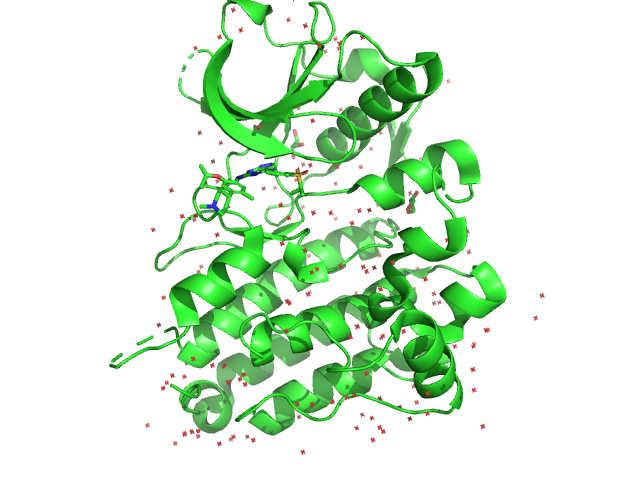

In [ ]:
from pymol import cmd
from IPython.display import Image
import os
os.environ['PYMOL_PATH'] = os.path.join(os.getcwd())
cmd.reinitialize()
cmd.fetch("4Z55")
cmd.orient("4Z55")
cmd.rotate("z","270")
cmd.png("image.png")
Image(filename = "image.png", unconfined=True)

**Figure 1.** ALK kinase domain (PDB 4Z55, 1.55 Å) with the cognate ligand 4LO

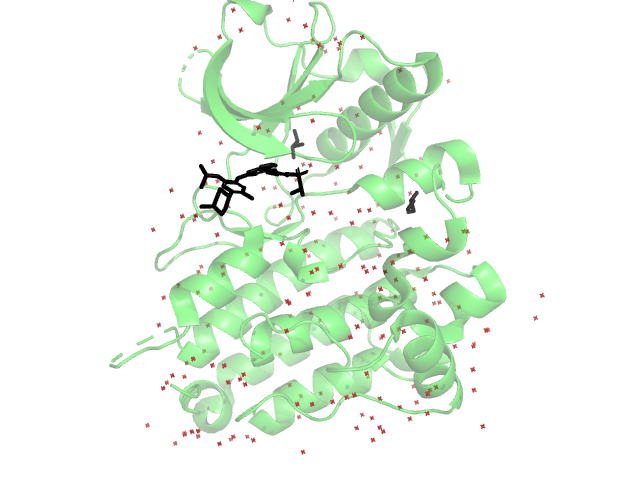

In [ ]:
cmd.color("black","organic")
cmd.set("cartoon_transparency",0.5)
cmd.png("image.png")
Image(filename = "image.png", unconfined=True)

**Figure 2.** ALK kinase domain (PDB 4Z55, 1.55 Å) with the cognate ligand (4LO) highlated in black.

##### 1.2.2 Find Residue Codes

In [ ]:
cmd.select("het", "organic")   # all small molecules
print(cmd.count_atoms("het"))
stored = []
cmd.iterate("het", "stored.append((resn, chain, resi))", space={"stored": stored})
print(sorted(set(stored)))

250
[('4LO', 'A', '1503'), ('GOL', 'A', '1501'), ('GOL', 'A', '1502'), ('HOH', 'A', '1601'), ('HOH', 'A', '1602'), ('HOH', 'A', '1603'), ('HOH', 'A', '1604'), ('HOH', 'A', '1605'), ('HOH', 'A', '1606'), ('HOH', 'A', '1607'), ('HOH', 'A', '1608'), ('HOH', 'A', '1609'), ('HOH', 'A', '1610'), ('HOH', 'A', '1611'), ('HOH', 'A', '1612'), ('HOH', 'A', '1613'), ('HOH', 'A', '1614'), ('HOH', 'A', '1615'), ('HOH', 'A', '1616'), ('HOH', 'A', '1617'), ('HOH', 'A', '1618'), ('HOH', 'A', '1619'), ('HOH', 'A', '1620'), ('HOH', 'A', '1621'), ('HOH', 'A', '1622'), ('HOH', 'A', '1623'), ('HOH', 'A', '1624'), ('HOH', 'A', '1625'), ('HOH', 'A', '1626'), ('HOH', 'A', '1627'), ('HOH', 'A', '1628'), ('HOH', 'A', '1629'), ('HOH', 'A', '1630'), ('HOH', 'A', '1631'), ('HOH', 'A', '1632'), ('HOH', 'A', '1633'), ('HOH', 'A', '1634'), ('HOH', 'A', '1635'), ('HOH', 'A', '1636'), ('HOH', 'A', '1637'), ('HOH', 'A', '1638'), ('HOH', 'A', '1639'), ('HOH', 'A', '1640'), ('HOH', 'A', '1641'), ('HOH', 'A', '1642'), ('HOH

In [ ]:
cmd.select("4Z55-ligand", "resn 4LO and chain A")
cmd.select("4Z55-receptor", "polymer.protein")

cmd.save("4Z55-ligand.pdb", "4Z55-ligand")
cmd.save("4Z55-receptor.pdb", "4Z55-receptor")

##### 1.2.3 Visualize Cognate Ligand

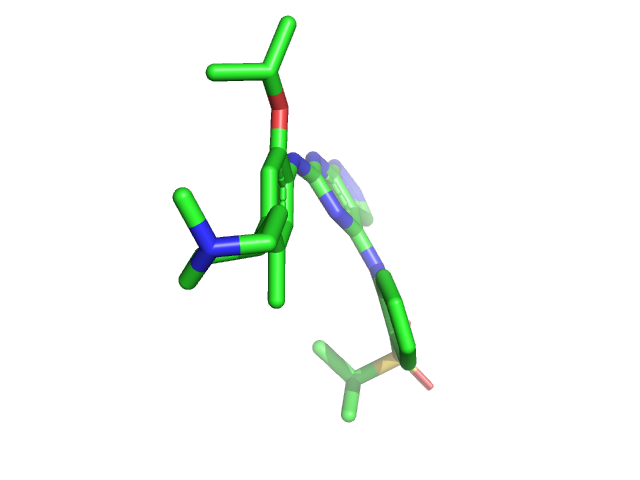

In [ ]:
cmd.reinitialize()
cmd.load("4Z55-ligand.pdb")
cmd.png("ligand.png")
Image(filename = "ligand.png", unconfined=True)

**Figure 3.** Close-up view of the cognate ligand 4LO, extracted from PDB 4Z55 (chain A). 4LO is a compound derived from ceritinib (LDK378) that has a pyrazolo[3,4-d]pyrimidine-4,6-diamine structure. It contains isopropoxy, methylpiperidine, and isopropylsulfonyl-phenyl substituents (Lee & Spraggon, 2016; RCSB PDB, n.d.).

##### 1.2.4 Visualize receptor

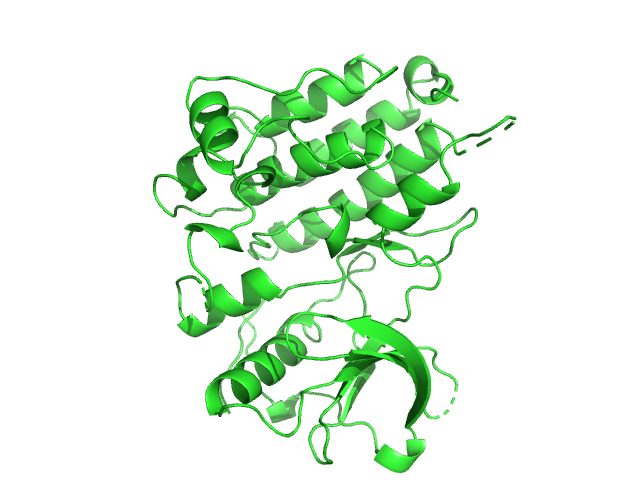

In [ ]:
#Now the receptor
cmd.reinitialize()
cmd.load("4Z55-receptor.pdb")
cmd.orient("4Z55-receptor")
cmd.rotate("z","270")
cmd.png("receptor.png")
Image(filename = "receptor.png", unconfined=True)

**Figure 4.** 4Z55 receptor (chain A) used for docking. The ligand 4LO, waters, and additional additves were removed.

#### 1.3 Visualize Hydrogen Bond Contacts

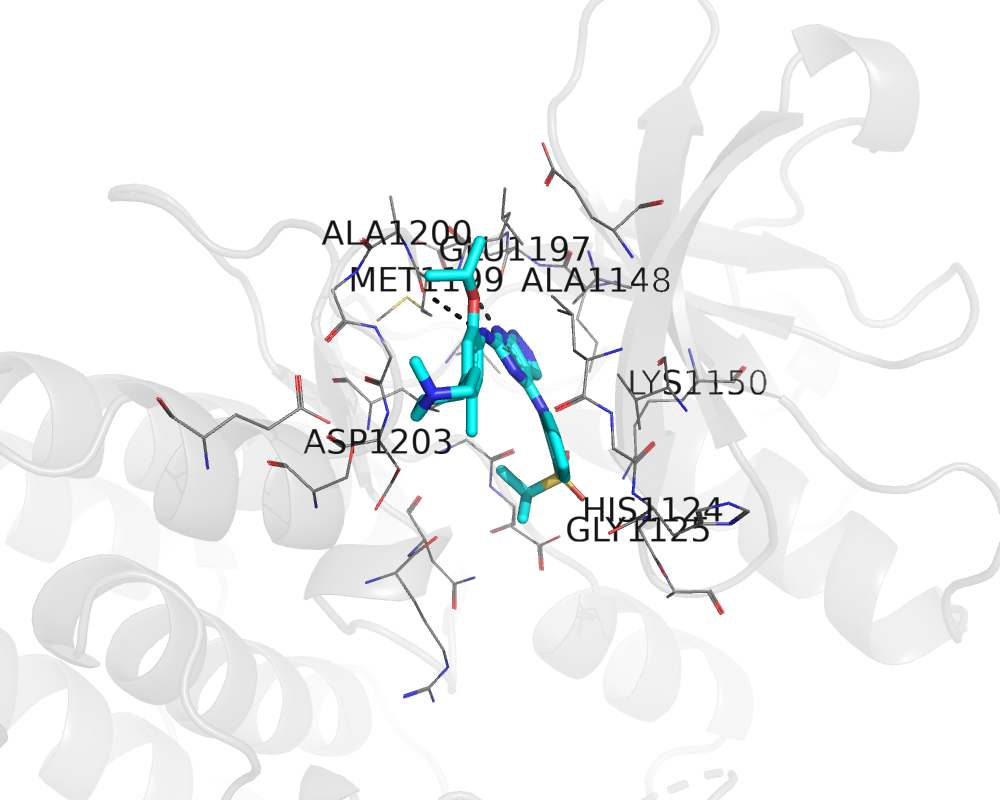

In [ ]:
#reload figure
cmd.reinitialize()
cmd.load("4Z55-receptor.pdb")
cmd.load("4Z55-ligand.pdb")

cmd.color("grey","4Z55-receptor")

#select sphere around the ligand and show the residues
cmd.select("pocketresidues", "byres (all within 5 of 4Z55-ligand)&polymer.protein")
cmd.show("line","pocketresidues")
cmd.show("stick","4Z55-ligand")
cmd.set("cartoon_transparency", 0.8)
cmd.util.cnc()

#Find hydrogen-bond contacts between the ligand and the pocket, 3.5 A cutoff
cmd.distance("hbonds", "4Z55-ligand", "pocketresidues", 3.5, mode=2)
cmd.set("dash_color", "black")
cmd.hide("labels", "hbonds")

#Label the pocket residues that make the contacts
cmd.select("hbond_residues", "byres (pocketresidues within 3.5 of 4Z55-ligand)")
cmd.label("hbond_residues and name CA", "resn+resi")
cmd.set("label_size", 20)
cmd.set("label_color", "black")
cmd.set("label_position", (0, 0, 2))

cmd.zoom("pocketresidues", 4)
cmd.png("4Z55-pocket.png", width=1000, height=800, dpi=200, ray=1)
Image(filename = "4Z55-pocket.png", unconfined=True)

**Figure 5.** Binding pocket of ALK in 4Z55 with the cognate ligand 4LO (cyan sticks). Black dashed lines mark polar contacts between the ligand and the protein within 3.5 Å. Labeled residues have at least one atom within 3.5 Å of the ligand. The interactions with the backbone atoms of Glu1197 and Met1199 are explained in the text.

In [ ]:
cmd.select("lig_polar", "4Z55-ligand and (elem N or elem O)")
cmd.select("rec_polar", "pocketresidues and (elem N or elem O)")
cmd.iterate("(rec_polar within 3.5 of lig_polar)", "print(resn, resi, name)")

GLU 1197 O
MET 1199 N
MET 1199 O

3

 **Hydrogen bond contacts** The ligand forms polar interactions with the backbone of Glu1197 and Met1199. These interactions are commonly seen in drugs that inhibit ATP binding of ALK, which support that the ligand is located in the ATP-binding pocket (Luca et al., 2022).

#### 1.4 Binding Pocket Description

In [ ]:
from pymol import cmd

cmd.reinitialize()
cmd.load("4Z55-receptor.pdb")
cmd.load("4Z55-ligand.pdb")

# Pocket residues: same selection as hydrogen-bond cell
cmd.select("pocketresidues", "byres (all within 5 of 4Z55-ligand)&polymer.protein")
cmd.iterate("pocketresidues and name CA", "print(resn, resi)")

# Check if ligand atom comes within 5 Å of residue 1281?
cmd.select("mut1281", "4Z55-receptor and resi 1281")
print("Ligand atoms within 5 Å of residue 1281:",
      cmd.count_atoms("4Z55-ligand within 5 of mut1281"))

LEU 1122
GLY 1123
HIS 1124
GLY 1125
ALA 1126
VAL 1130
GLU 1132
ALA 1148
LYS 1150
VAL 1180
LEU 1196
GLU 1197
LEU 1198
MET 1199
ALA 1200
GLY 1201
GLY 1202
ASP 1203
SER 1206
GLU 1210
ARG 1253
ASN 1254
LEU 1256
GLY 1269
ASP 1270
Ligand atoms within 5 Å of residue 1281: 0

**Binding pocket description** 25 residues have an atom within 5 Å of the cognate ligand 4LO. The ligand binds in the ALK pocket and forms polar interactions with the backbone of Glu1197 and Met1199 in the hinge region. The pocket also includes Leu1196 and Gly1202, which are two residues associated with resistance to ALK inhibitors. Mutations at these positions (i.e. G1202R) can affect how well inhibitors bind to ALK (Yoda et al., 2018).

### 2. Virtual Screen Library Selection

#### 2.1 Load Library

In [ ]:
from rdkit import Chem
from rdkit.Chem import PandasTools
import pandas as pd

library = PandasTools.LoadSDF("Week6-VirtualLibrary.sdf")
print(f"Total number of molecules in library: {len(library)}")
library.head()

Total number of molecules in library: 18748

,identifier,ID,ROMol
0,ZINC000009160514,ZINC000009160514,<rdkit.Chem.rdchem.Mol object at 0x7aa54fa9ed50>
1,ZINC000585104165,ZINC000585104165,<rdkit.Chem.rdchem.Mol object at 0x7aa54fa9f1b0>
2,ZINC000016385159,ZINC000016385159,<rdkit.Chem.rdchem.Mol object at 0x7aa54fa9f140>
3,ZINC000008664075,ZINC000008664075,<rdkit.Chem.rdchem.Mol object at 0x7aa54fa9f060>
4,ZINC000017223674,ZINC000017223674,<rdkit.Chem.rdchem.Mol object at 0x7aa54fa9f220>


#### 2.3 Visualize molecules as a grid

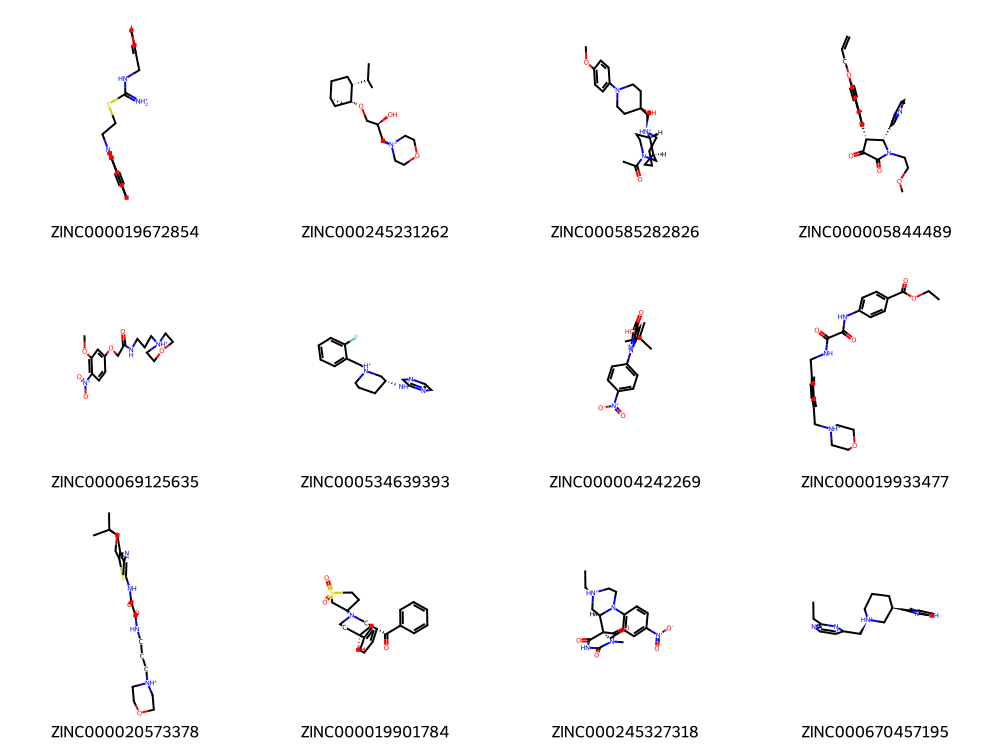

In [ ]:
from rdkit.Chem import Draw
sample = library.sample(12, random_state=1)
legends = [row["ID"] for _, row in sample.iterrows()]
Draw.MolsToGridImage(list(sample["ROMol"]), molsPerRow=4, legends=legends, subImgSize=(250, 250))

**Figure 6.** Twelve compounds randomly selected (seed = 1) from the provided library before cleaning (18,748 compounds), labeled with their ZINC IDs. The library is very diverse and ranges from small, flexible molecules to larger molecules with multiple rings. Several compounds also contain nitro groups or positively charged amine groups (NH⁺).

#### 2.2 Cleaning and Filtering Compound List

##### 2.2.1 Desalting

In [ ]:
from rdkit import Chem
from rdkit.Chem.MolStandardize import rdMolStandardize

chooser = rdMolStandardize.LargestFragmentChooser()

# Count molecules with more than one fragment (salts / counterions) before desalting
n_multi = sum(len(Chem.GetMolFrags(m)) > 1 for m in library["ROMol"])

# Keep only the largest fragment of each molecule
library["ROMol"] = library["ROMol"].apply(chooser.choose)

print(f"Molecules in library:                    {len(library)}")
print(f"Molecules with >1 fragment (desalted):   {n_multi}")

Molecules in library:                    18748
Molecules with >1 fragment (desalted):   0

##### 2.2.2 Canonicalize, drop failures and duplicates

In [ ]:
from rdkit import Chem

# Canonicalize SMILES (his function), then drop failures and duplicates
def canonicalize(mol):
    if mol is None:
        return None
    return Chem.MolToSmiles(mol, canonical=True)

n0 = len(library)
library["canonical_smiles"] = library["ROMol"].apply(canonicalize)
library = library.dropna(subset=["canonical_smiles"])
n1 = len(library)
library = library.drop_duplicates(subset="canonical_smiles", keep="first").reset_index(drop=True)
n2 = len(library)

print(f"Loaded:                   {n0}")
print(f"After dropping failures:  {n1}")
print(f"After removing duplicates:{n2}  ({n1 - n2} duplicates removed)")

Loaded:                   18748
After dropping failures:  18748
After removing duplicates:17759  (989 duplicates removed)

##### 2.2.3 PAINS filtering

In [ ]:
from rdkit.Chem.FilterCatalog import FilterCatalog, FilterCatalogParams

params = FilterCatalogParams()
params.AddCatalog(FilterCatalogParams.FilterCatalogs.PAINS)
pains = FilterCatalog(params)

library["PAINS"] = library["ROMol"].apply(pains.HasMatch)

print(f"PAINS-flagged: {library['PAINS'].sum()} of {len(library)}")
library_clean = library[~library["PAINS"]].reset_index(drop=True)
print(f"After removing PAINS: {len(library_clean)}")

PAINS-flagged: 4468 of 17759
After removing PAINS: 13291

##### 2.2.4 Visualize cleaned library

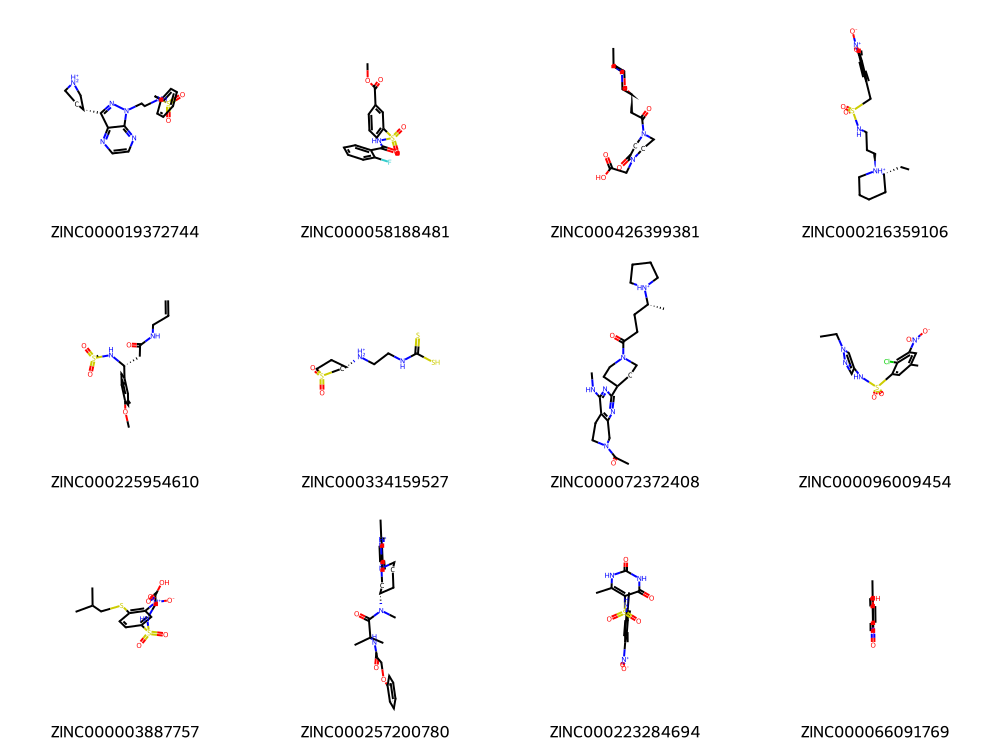

In [ ]:
   from rdkit.Chem import Draw
   sample = library_clean.sample(12, random_state=1)
   legends = [row["ID"] for _, row in sample.iterrows()]
   Draw.MolsToGridImage(list(sample["ROMol"]), molsPerRow=4, legends=legends, subImgSize=(250, 250))

**Figure 7.** Twelve compounds randomly selected (seed = 1) from the cleaned library of 13,291 compounds, labeled with their ZINC IDs. The library was cleaned by desalting (no molecules with multiple fragments were found), canonicalizing SMILES and removing duplicates (989 removed), and removing compounds flagged by the PAINS filter (4,468 removed).

#### 2.3 Assess Descriptors

In [ ]:
from rdkit.Chem import Descriptors, Crippen, Lipinski, rdMolDescriptors
from rdkit import Chem

def calc(m):
    return pd.Series({
        "MW": Descriptors.MolWt(m),
        "cLogP": Crippen.MolLogP(m),
        "HBD": Lipinski.NumHDonors(m),
        "HBA": Lipinski.NumHAcceptors(m),
        "TPSA": rdMolDescriptors.CalcTPSA(m),
        "RotBonds": Lipinski.NumRotatableBonds(m),
        "Rings": rdMolDescriptors.CalcNumRings(m),
    })

desc = library_clean["ROMol"].apply(calc)
library_clean = pd.concat([library_clean, desc], axis=1)
library_clean[desc.columns].describe().round(2)

,MW,cLogP,HBD,HBA,TPSA,RotBonds,Rings
count,13291.00,13291.00,13291.00,13291.00,13291.00,13291.00,13291.00
mean,358.09,0.70,2.06,5.47,102.75,5.15,2.80
std,54.44,1.64,1.43,1.87,36.10,2.14,1.03
min,250.07,-7.56,0.00,0.00,9.23,0.00,0.00
25%,316.30,-0.42,1.00,4.00,76.72,4.00,2.00
50%,356.17,0.90,2.00,5.00,99.84,5.00,3.00
75%,402.59,2.04,3.00,7.00,124.44,6.00,3.00
max,676.89,6.35,11.00,16.00,323.68,24.00,9.00


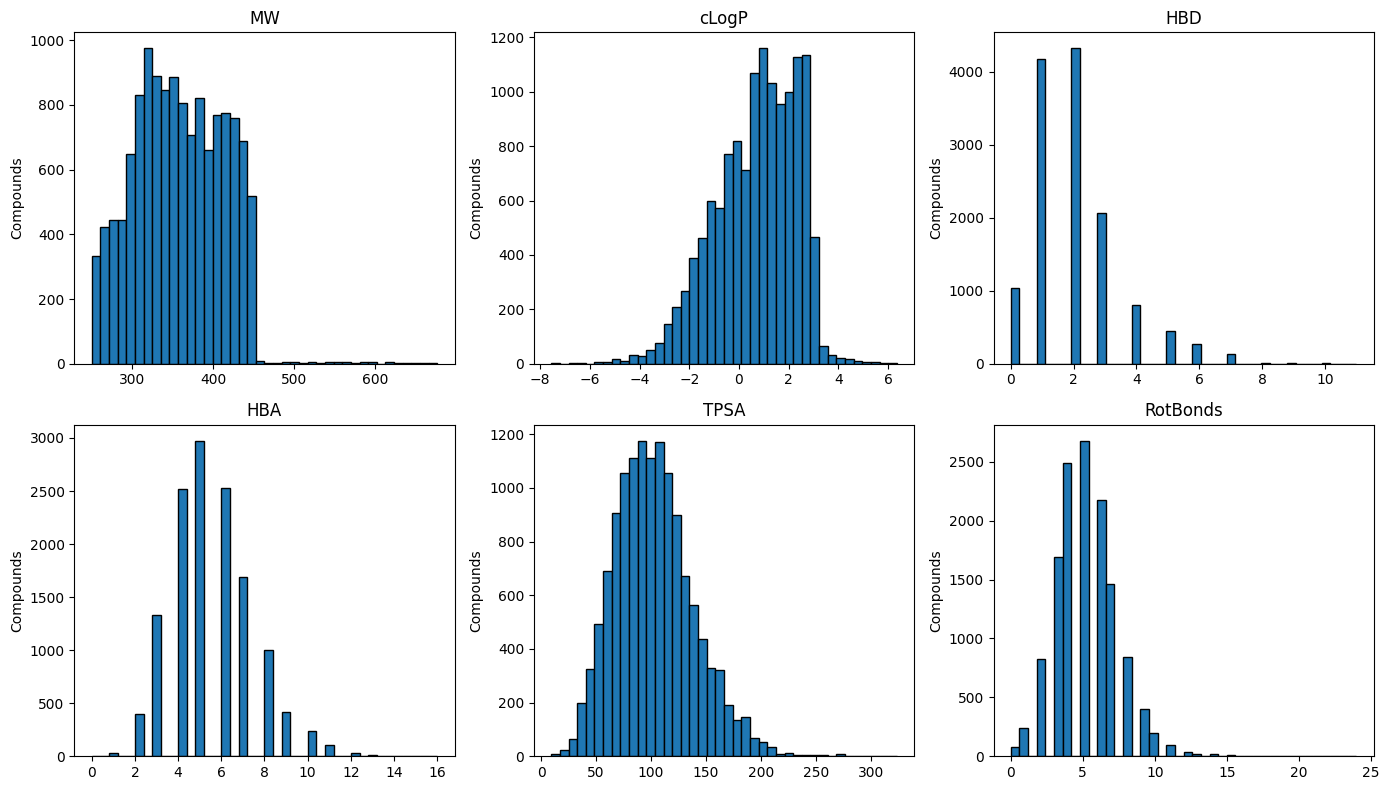

In [ ]:
import matplotlib.pyplot as plt

cols = ["MW", "cLogP", "HBD", "HBA", "TPSA", "RotBonds"]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, c in zip(axes.flat, cols):
    ax.hist(library_clean[c], bins=40, edgecolor="black")
    ax.set_title(c)
    ax.set_ylabel("Compounds")
plt.tight_layout()
plt.savefig("library_descriptors.png", dpi=200)
plt.show()

**Figure 8.** Molecular descriptors of the cleaned library. Distributions of six descriptors
for the 13,291 compounds after cleaning: molecular weight (MW), cLogP, hydrogen-bond donors (HBD), hydrogen-bond acceptors (HBA), topological polar surface area (TPSA) and rotatable bonds (RotBonds).

After desalting, de-duplication and PAINS filtering, the library contains 13,291 compounds. Most were relatively small (MW 250–450 Da), moderately polar (average cLogP of 0.7 and TPSA of 103 Å²) and moderately flexibile (about 5 rotatable bonds). Most had 1–2 hydrogen-bond donors and around 5 hydrogen-bond acceptors.

#### 2.4 Save Cleaned Library as SDF file for Docking

The library was provided as an SDF file with 3D coordinates for all 13,291 compounds remaining after cleaning. Since the compounds already had 3D structures, there was no need to convert them from SMILES. The library was saved as an SDF file for docking with smina.

In [ ]:
from rdkit import Chem

w = Chem.SDWriter("library_clean.sdf")
for _, row in library_clean.iterrows():
    m = row["ROMol"]
    m.SetProp("_Name", str(row["ID"]))
    m.SetProp("ID", str(row["ID"]))
    w.write(m)
w.close()
print("Done")

Done

#### 2.5 Estimate Completion Time for Smina-Virtual Screen

In [ ]:
!wget https://sourceforge.net/projects/smina/files/smina.static/download -O smina.static
!chmod u+x smina.static

2026-10-17 20:35:15 (45.8 MB/s) - ‘smina.static’ saved [9853920/9853920]

In [ ]:
import time
from rdkit import Chem

# write 10 compounds to a small test file
w = Chem.SDWriter("test10.sdf")
for m in library_clean["ROMol"].sample(10, random_state=1):
    w.write(m)
w.close()

# his smina command, with timing around it
start = time.time()
!./smina.static -r 4Z55-receptor.pdb -l test10.sdf --autobox_ligand 4Z55-ligand.pdb -o test10_out.sdf --exhaustiveness 1 --num_modes 1 -q
elapsed = time.time() - start

print(f"{elapsed:.1f} s for 10 compounds ({elapsed/10:.1f} s per compound)")
print(f"Estimated time for {len(library_clean)} compounds: {elapsed/10*len(library_clean)/3600:.1f} hours")

Loop time 107.433
107.7 s for 10 compounds (10.8 s per compound)
Estimated time for 13291 compounds: 39.8 hours

Docking all 13,291 compounds was estimated to take about 40 hours, with each compound taking around 10.8 seconds. Since this would exceed Google Colab’s session limits, a random sample of 500 compounds was selected for screening using a random seed of 42.

### 3. Method Validation

#### 3.1 Redock Ligand

##### 3.1.1 Build the Ligand from SMILES

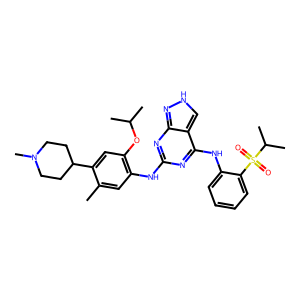

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [ ]:
from rdkit import Chem
from rdkit.Chem import AllChem, Draw
import py3Dmol

# Paste the 4LO SMILES from https://www.rcsb.org/ligand/4LO
lig = Chem.MolFromSmiles("Cc1cc(c(cc1C2CCN(CC2)C)OC(C)C)Nc3nc4c(c[nH]n4)c(n3)Nc5ccccc5S(=O)(=O)C(C)C")
display(Draw.MolToImage(lig, size=(300, 300)))

# add hydrogens, embed in 3D, and minimize
lig = Chem.AddHs(lig, addCoords=True)
AllChem.EmbedMolecule(lig)
AllChem.MMFFOptimizeMolecule(lig)

# view the 3D result
mblock = Chem.MolToMolBlock(lig)
view = py3Dmol.view(data=mblock, style={"stick": {}, "sphere": {"scale": 0.3}})
view.zoomTo()
view.show()

# save as SDF
file = Chem.SDWriter("newligand.sdf")
file.write(lig)
file.close()

**Figure 9.** The cognate ligand 4LO rebuilt from its SMILES string for redocking. The top image shows its 2D structure, and the bottom shows the 3D structure created using RDKit.  Hydrogens were added, the molecule was converted into 3D, and optimized with MMFF (RCSB Ligand Expo, OpenEye canonical SMILES).

##### 3.1.2 Smina Redocking Run

In [ ]:
!./smina.static -r 4Z55-receptor.pdb -l newligand.sdf --autobox_ligand 4Z55-ligand.pdb -o 4Z55-ligand-poses.sdf

mode |   affinity | dist from best mode
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
1       -9.3       0.000      0.000    
2       -9.0       1.270      2.915    
3       -8.8       3.022      5.665    
4       -8.8       1.359      2.354    
5       -8.7       3.854      10.355   
6       -8.6       2.737      5.107    
7       -8.6       2.313      4.248    
8       -8.5       2.061      3.649    
9       -8.4       3.263      5.643    
Refine time 220.802
Loop time 221.754

The rebuilt 4LO ligand was docked back into the binding pocket of 4Z55 using smina.This run used smina's default settings, not the exhaustiveness of 1 used for the screen, and returned nine poses. The best pose scored
-9.3 kcal/mol, and is used the reference score for the cognate ligand. The RMSD values compare each pose to the best-scoring docking pose, not to the original crystal structure.

,minimizedAffinity,ID,ROMol
0,-9.30184,,
1,-9.01688,,
2,-8.81908,,
3,-8.81376,,
4,-8.65855,,
5,-8.64253,,
6,-8.57178,,
7,-8.52451,,
8,-8.38366,,

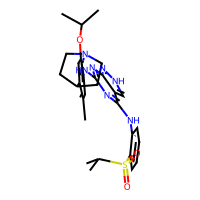
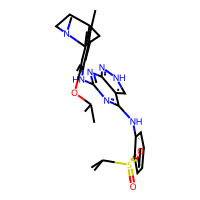
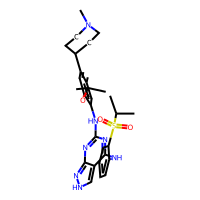
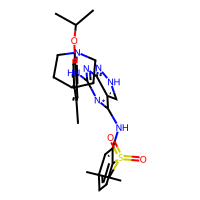
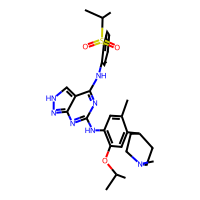
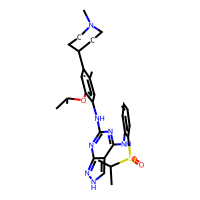
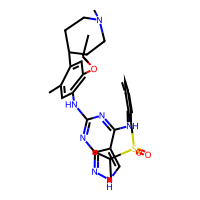
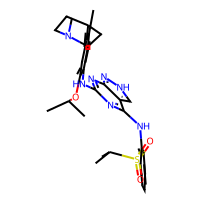
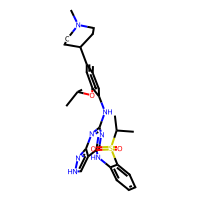

In [ ]:
from rdkit.Chem import PandasTools
dockedposes = PandasTools.LoadSDF("4Z55-ligand-poses.sdf")
dockedposes

##### 3.1.3 Compare the Best Redocked Pose with the Crystal Pose

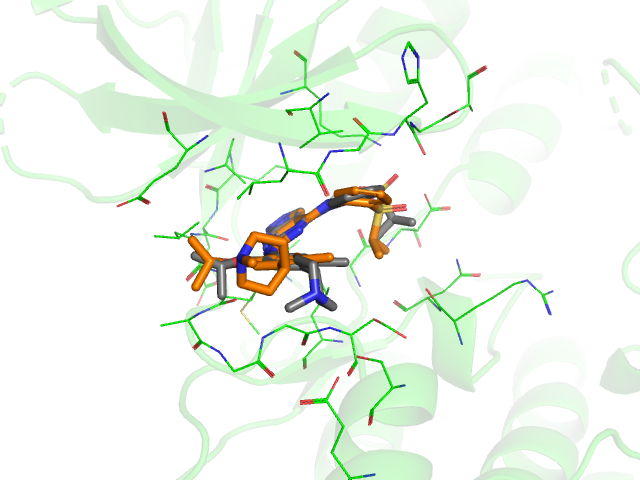

In [ ]:
#Wipe the memory and load into the workspace
cmd.reinitialize()
cmd.load("4Z55-receptor.pdb")
cmd.load("4Z55-ligand.pdb")
cmd.load("4Z55-ligand-poses.sdf")

cmd.color("green", "4Z55-receptor")          #color the protein green
cmd.color("grey", "4Z55-ligand")             #color the original (crystal) pose grey
cmd.color("orange", "4Z55-ligand-poses")     #color the docked poses orange

#We will create a selection sphere around the ligand and show the residues
cmd.select("pocketresidues", "byres (all within 5 of 4Z55-ligand)&polymer.protein")
cmd.show("line", "pocketresidues")
cmd.set("ray_shadow", 0)
cmd.set("cartoon_transparency", 0.8)
cmd.util.cnc()
cmd.zoom("pocketresidues")                   #zoom in on only the pocket
cmd.rotate("z", "90")

camera = cmd.get_view()                      #save the camera viewpoint

#display the best pose
cmd.png("pose.png")
Image(filename="pose.png", unconfined=True)

**Figure 10.** Redocking of the cognate ligand 4LO into the 4Z55 pocket. The crystal pose is shown as grey sticks and the best-scoring docked pose (-9.3 kcal/mol) as orange sticks. The receptor is shown in green, with residues within 5 Å of the ligand as
lines.

The orange and grey ligands overlap pretty well in the central region and near the group at the upper right. However, the group on the left side (methylpiperidine) is positioned slightly differently. This means that the docked ligand binds in a similar position to the original crystal ligand, with only slight differences in the position of the methylpiperidine group. To compare them more accurately, the RMSD between the docked ligand and the original crystal ligand would need to be calculated.

#### 3.2 Download ALK activity data from ChEMBL

In [ ]:
import pandas as pd
import requests
import time

all_activities = []
url = "https://www.ebi.ac.uk/chembl/api/data/activity.json?target_chembl_id=CHEMBL4247&limit=1000&offset=0"

while url:
    try:
        response = requests.get(url, timeout=30)
        response.raise_for_status()
        data = response.json()
    except Exception as e:
        print(f"Error: {e}")
        break

    all_activities.extend(data['activities'])
    print(f"Fetched {len(all_activities)} records so far...")

    next_page = data['page_meta'].get('next')
    url = f"https://www.ebi.ac.uk{next_page}" if next_page else None

    time.sleep(0.5)

alkdata = pd.DataFrame(all_activities)
alkdata = alkdata.dropna(subset=['canonical_smiles'])
print(f"Total records after filtering: {len(alkdata)}")
alkdata.head()

Fetched 1000 records so far...
Fetched 2000 records so far...
Fetched 3000 records so far...
Fetched 4000 records so far...
Fetched 5000 records so far...
Fetched 6000 records so far...
Fetched 7000 records so far...
Fetched 8000 records so far...
Fetched 9000 records so far...
Fetched 9838 records so far...
Total records after filtering: 9835

,action_type,activity_comment,activity_id,activity_properties,assay_chembl_id,assay_description,assay_type,assay_variant_accession,assay_variant_mutation,bao_endpoint,...,target_organism,target_pref_name,target_tax_id,text_value,toid,type,units,uo_units,upper_value,value
0,None,None,1675255,[],CHEMBL867052,Inhibitory activity against ALK,B,None,None,BAO_0000190,...,Homo sapiens,ALK tyrosine kinase receptor,9606,None,None,IC50,uM,UO_0000065,None,0.4
1,None,None,1675257,[],CHEMBL867052,Inhibitory activity against ALK,B,None,None,BAO_0000192,...,Homo sapiens,ALK tyrosine kinase receptor,9606,None,None,Ki,uM,UO_0000065,None,0.2
2,None,None,1675268,[],CHEMBL867052,Inhibitory activity against ALK,B,None,None,BAO_0000190,...,Homo sapiens,ALK tyrosine kinase receptor,9606,None,None,IC50,uM,UO_0000065,None,40.0
3,None,None,1675270,[],CHEMBL867052,Inhibitory activity against ALK,B,None,None,BAO_0000190,...,Homo sapiens,ALK tyrosine kinase receptor,9606,None,None,IC50,uM,UO_0000065,None,26.8
4,None,None,1675272,[],CHEMBL867052,Inhibitory activity against ALK,B,None,None,BAO_0000190,...,Homo sapiens,ALK tyrosine kinase receptor,9606,None,None,IC50,uM,UO_0000065,None,20.3


#### 3.3 Label actives and inactives

In [ ]:
from rdkit import Chem
from rdkit.Chem import AllChem, DataStructs

# Canonicalize SMILES before doing anything else (his function)
def canonicalize(smi):
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return None
    return Chem.MolToSmiles(mol, canonical=True)

alkdata['pchembl_value'] = pd.to_numeric(alkdata['pchembl_value'], errors='coerce')
alkdata['standard_value'] = pd.to_numeric(alkdata['standard_value'], errors='coerce')

# the cognate ligand (4LO), replacing his phenyl melatonin
cognate = pd.DataFrame({"canonical_smiles": ["Cc1cc(c(cc1C2CCN(CC2)C)OC(C)C)Nc3nc4c(c[nH]n4)c(n3)Nc5ccccc5S(=O)(=O)C(C)C"]})

# ---- actives: pChEMBL > 8 (his cutoff) ----
actives = alkdata.loc[alkdata['pchembl_value'] > 8, ['canonical_smiles']].copy()
actives = pd.concat([actives, cognate])
actives = actives.dropna(subset=['canonical_smiles'])
actives['canonical_smiles'] = actives['canonical_smiles'].apply(canonicalize)
actives = actives.dropna(subset=['canonical_smiles'])
actives = actives.drop_duplicates(subset='canonical_smiles', keep="first")

# ---- inactives: > 10 uM (the assignment's cutoff) ----
inactives = alkdata.loc[
    (alkdata['standard_type'].isin(['IC50', 'Ki', 'Kd'])) &
    (alkdata['standard_units'] == 'nM') &
    (alkdata['standard_value'] > 10000) &
    (alkdata['standard_relation'].isin(['=', '>', '>='])),
    ['canonical_smiles']].copy()
inactives['canonical_smiles'] = inactives['canonical_smiles'].apply(canonicalize)
inactives = inactives.dropna(subset=['canonical_smiles'])
inactives = inactives.drop_duplicates(subset='canonical_smiles', keep="first")

# remove any compound that ended up in both groups
both = set(actives['canonical_smiles']) & set(inactives['canonical_smiles'])
actives = actives[~actives['canonical_smiles'].isin(both)]
inactives = inactives[~inactives['canonical_smiles'].isin(both)]

# ---- similarity to the cognate ligand (his code) ----
fpgen = AllChem.GetMorganGenerator()
query = Chem.MolFromSmiles(canonicalize(cognate['canonical_smiles'][0]))
queryfp = fpgen.GetFingerprint(query)

def add_sim(df, label):
    sim = []
    for x in df.canonical_smiles:
        target = Chem.MolFromSmiles(x)
        sim.append(None if target is None else DataStructs.TanimotoSimilarity(fpgen.GetFingerprint(target), queryfp))
    df = df.copy()
    df["Active"] = label
    df["Sim"] = sim
    df = df.rename(columns={'canonical_smiles': 'smiles'})
    return df.sort_values("Sim", ascending=False)

actives = add_sim(actives, "True")
inactives = add_sim(inactives, "False")

print(f"Actives (pChEMBL > 8):    {len(actives)}")
print(f"Inactives (> 10 uM):      {len(inactives)}")
print(f"Removed (in both groups): {len(both)}")
actives

Actives (pChEMBL > 8):    890
Inactives (> 10 uM):      233
Removed (in both groups): 4

,smiles,Active,Sim
0,Cc1cc(Nc2nc(Nc3ccccc3S(=O)(=O)C(C)C)c3c[nH]nc3...,True,1.000000
6048,Cc1cc(Nc2nc(Nc3ccccc3S(=O)(=O)C(C)C)c3cc[nH]c3...,True,0.736364
6045,Cc1cc(Nc2nc(Nc3ccccc3S(=O)(=O)C(C)C)c3c(C)[nH]...,True,0.710526
3953,Cc1cc(Nc2nc(Nc3ccccc3S(=O)(=O)C(C)C)c3c(C)c[nH...,True,0.684211
3934,COc1cc(C2CCN(C)CC2)c(C)cc1Nc1nc(Nc2ccccc2S(=O)...,True,0.608333
...,...,...,...
4149,COc1cc2c(cc1C#CC(=O)O)C(=O)c1c([nH]c3cc(C#N)cc...,True,0.069182
4708,NC(=O)c1ccc(N(C(N)=O)c2c(F)cccc2F)nc1-c1ccc(F)...,True,0.068966
298,CCN(CC)CCOc1ccc2c(c1)C(C)(C)c1[nH]c3cc(C#N)ccc...,True,0.068323
4132,CC1(C)c2cc(C(=O)NCCNS(N)(=O)=O)ccc2C(=O)c2c1[n...,True,0.066667


#### 3.4 Ligand Preparation and Subsample

150 compounds were docked for method validation. This includes a a random sample of 50 known actives (from 890 ChEMBL compounds with pChEMBL > 8) and 100 known inactives (from 233 compounds with activity > 10 µM), both from the ALK dataset (CHEMBL4247).

In [ ]:
import numpy as np
from rdkit.Chem import AllChem, PandasTools
from rdkit.Chem.MolStandardize import rdMolStandardize

chooser = rdMolStandardize.LargestFragmentChooser()

# random subsample (seed so it's reproducible)
vsmols = pd.concat([actives.sample(50, random_state=42),
                    inactives.sample(100, random_state=42)]).reset_index(drop=True)
vsmols["ID"] = ["Molecule_" + str(i) for i in range(len(vsmols))]

# his Convert3D, plus desalting (largest fragment) and a check for failures
def Convert3D(molsmile):
    mol = Chem.MolFromSmiles(molsmile)
    if mol is None:
        return None
    mol = chooser.choose(mol)                        # strip salts
    mol = Chem.AddHs(mol, addCoords=True)
    if AllChem.EmbedMolecule(mol, randomSeed=42) != 0:
        return None
    try:
        AllChem.MMFFOptimizeMolecule(mol)
    except Exception:
        return None
    return mol

vsmols["minim"] = [Convert3D(s) for s in vsmols.smiles]
print("Failed 3D conversion:", vsmols["minim"].isna().sum())
vsmols = vsmols.dropna(subset=["minim"]).reset_index(drop=True)

print(f"Molecules to dock: {len(vsmols)}  "
      f"({(vsmols.Active=='True').sum()} actives, {(vsmols.Active=='False').sum()} inactives)")

PandasTools.WriteSDF(vsmols, out="dockingligands.sdf", molColName='minim',
                     idName='ID', properties=None, allNumeric=False, forceV3000=False)

Failed 3D conversion: 0
Molecules to dock: 150  (50 actives, 100 inactives)

#### 3.5 Dock with Smina

In [ ]:
!./smina.static -r 4Z55-receptor.pdb -l dockingligands.sdf --autobox_ligand 4Z55-ligand.pdb -o virtualscreen.sdf --exhaustiveness 1 --num_modes 1 -q

Loop time 3665

#### 3.6 Merge scores with labels by ID

In [ ]:
vsresults = PandasTools.LoadSDF("virtualscreen.sdf")

merged = vsmols.merge(vsresults, left_on="ID", right_on="ID")
merged = merged[['ID', 'Active', 'Sim', 'minimizedAffinity']]
merged['minimizedAffinity'] = pd.to_numeric(merged['minimizedAffinity'], errors='coerce')
merged = merged.sort_values('minimizedAffinity', ascending=True)
merged

,ID,Active,Sim,minimizedAffinity
16,Molecule_16,True,0.142857,-10.01487
41,Molecule_41,True,0.094340,-9.93812
2,Molecule_2,True,0.371429,-9.86566
15,Molecule_15,True,0.154321,-9.82526
139,Molecule_139,False,0.121795,-9.76341
...,...,...,...,...
73,Molecule_73,False,0.081967,-5.87493
144,Molecule_144,False,0.057851,-5.86227
99,Molecule_99,False,0.055118,-5.81920
82,Molecule_82,False,0.064000,-5.69034


The four compounds with the best docking scores (-10.01 to -9.83 kcal/mol) were all known active compounds. The highest-scoring inactive compound (Molecule_139, -9.76 kcal/mol) ranked fifth. The top active compounds had a low similarity to 4LO (0.09–0.37), which shows that method can find compounds with different chemical structures, not just ones that are similar to the original ligand.

#### 3.7 ROC plot and AUC

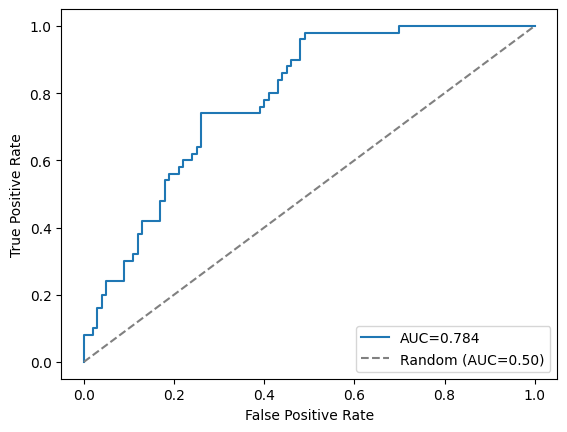

In [ ]:
from sklearn import metrics
import matplotlib.pyplot as plt

merged.replace({"False": 0, "True": 1}, inplace=True)

fpr, tpr, _ = metrics.roc_curve(merged['Active'], -merged['minimizedAffinity'])
auc = metrics.roc_auc_score(merged['Active'], -merged['minimizedAffinity'])

plt.plot(fpr, tpr, label=f"AUC={auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle='--', color='grey', label="Random (AUC=0.50)")
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.legend(loc=4)
plt.show()

**Figure 11.** ROC curve showing how well the 4Z55 binding pocket identifies active ALK inhibitors. 50 known ALK actives(pChEMBL > 8) and 100 known inactives (> 10 µM) from ChEMBL (CHEMBL4247) were docked with
smina and ranked by docking score. The blue curve shows the percentage of active compounds correctly identified (0.784), and thhe grey line shows random ranking (AUC = 0.50).

Ranking the 150 validation compounds by smina score gave
an AUC of 0.784 (Figure 11). This means that the method had about a 78% chance of ranking an active compound higher than an inactive one, compared to 50% for random ranking. The method wasn't perfect and is most likely affected by the small sample size, but the results suggest that the docking setup is reasonably effective at identifying active ALK inhibitors in the 4Z55 binding pocket.

### 4. Smina-Virtual Screen

##### 4.1 Smina Overview

Smina is a free, open-source molecular docking program based on AutoDock Vina. It includes features for scoring, improving ligand positions, and setting up docking searches. One useful feature is --autobox_ligand, which automatically sets the docking search area around a reference ligand (Koes et al., 2013).


Smina tests different positions of a flexible ligand within a rigid protein structure to find the best fit (Trott & Olson, 2010). It scores each position based on hydrogen bonding, hydrophobic interactions, and how closely the atoms fit together. Docking scores are reported in kcal/mol, and more negative values indicate a stronger predicted binding.

The --exhaustiveness setting controls how much smina searches for different binding positions, and --num_modes controls the number of docking poses returned.

For this project, the search box was centered around the original cognate ligand, 4LO, from the 4Z55 structure.

##### 4.2 Prepare the library sample

In [ ]:
from rdkit import Chem

library_sample = library_clean.sample(500, random_state=42).reset_index(drop=True)
print(f"Sampled {len(library_sample)} of {len(library_clean)} compounds (random_state=42)")

w = Chem.SDWriter("library_sample.sdf")
for _, row in library_sample.iterrows():
    m = Chem.AddHs(row["ROMol"], addCoords=True)
    m.SetProp("_Name", str(row["ID"]))
    m.SetProp("ID", str(row["ID"]))
    w.write(m)
w.close()
print("Wrote library_sample.sdf")

Sampled 500 of 13291 compounds (random_state=42)
Wrote library_sample.sdf

#### 4.3 Split the Data and Downsample

The sample was split into two batches of 250 compounds and docked separately using the same settings as the validation set (original ligand search box, exhaustiveness of 1, and one pose per compound). The results from both batches were then merged for analysis.

In [ ]:
def write_chunk(df, filename):
    w = Chem.SDWriter(filename)
    for _, row in df.iterrows():
        m = Chem.AddHs(row["ROMol"], addCoords=True)
        m.SetProp("_Name", str(row["ID"]))
        m.SetProp("ID", str(row["ID"]))
        w.write(m)
    w.close()

write_chunk(library_sample.iloc[:250], "library_chunk1.sdf")
write_chunk(library_sample.iloc[250:], "library_chunk2.sdf")
print("Wrote library_chunk1.sdf and library_chunk2.sdf (250 compounds each)")

Wrote library_chunk1.sdf and library_chunk2.sdf (250 compounds each)

#### 4.4 Run Smina

##### 4.4.1 Smina Batch 1 Run

In [ ]:
import time
start = time.time()
!./smina.static -r 4Z55-receptor.pdb -l library_chunk1.sdf --autobox_ligand 4Z55-ligand.pdb -o library_screen1.sdf --exhaustiveness 1 --num_modes 1 -q
print(f"Chunk 1 took {(time.time()-start)/60:.1f} minutes")

Loop time 2523.08
Chunk 1 took 42.1 minutes

##### 4.4.2 Smina Batch 2 Run

In [ ]:
start = time.time()
!./smina.static -r 4Z55-receptor.pdb -l library_chunk2.sdf --autobox_ligand 4Z55-ligand.pdb -o library_screen2.sdf --exhaustiveness 1 --num_modes 1 -q
print(f"Chunk 2 took {(time.time()-start)/60:.1f} minutes")

Loop time 2405.56
Chunk 2 took 40.1 minutes

#### 4.5 Load and analyze the results

In [ ]:
import pandas as pd
from rdkit.Chem import PandasTools

res1 = PandasTools.LoadSDF("library_screen1.sdf")
res2 = PandasTools.LoadSDF("library_screen2.sdf")
vsresults = pd.concat([res1, res2], ignore_index=True)
print(f"Docked results loaded: {len(vsresults)} (expected 500)")

libscores = library_sample[['ID', 'canonical_smiles']].merge(vsresults[['ID', 'minimizedAffinity']], on="ID")
libscores['minimizedAffinity'] = pd.to_numeric(libscores['minimizedAffinity'], errors='coerce')
libscores = libscores.sort_values('minimizedAffinity', ascending=True).reset_index(drop=True)
print(f"Compounds with a score: {libscores['minimizedAffinity'].notna().sum()}")
libscores.head(10)

Docked results loaded: 500 (expected 500)
Compounds with a score: 500

,ID,canonical_smiles,minimizedAffinity
0,CHEMBL3934738_8.52,COc1cc(N2CCN(C)CC2)ccc1Nc1ncc(C(F)(F)F)c(Nc2cc...,-9.54883
1,ZINC000020869469,COc1ccc2oc(=O)cc(CN3CCN(C(=O)c4n[nH]c5c4CCCC5)...,-9.41607
2,ZINC000002104998,Cc1c(OCC(=O)N2CCC[C@H]2C(=O)O)ccc2c3c(c(=O)oc1...,-9.27840
3,ZINC000009009863,C[C@@H]1CN2c3ccc([N+](=O)[O-])cc3C[C@]3(C(=O)N...,-9.19413
4,ZINC000585150118,Cc1cc(=O)[nH]c(-n2nc(C)cc2NC(=O)[C@@H](C)n2nc3...,-8.94553
5,ZINC000016000528,O=C1[C@@H]2[C@@H](C(=O)N1c1cccc([N+](=O)[O-])c...,-8.85111
6,ZINC000008790788,O=C(COc1ccc2c(c1)O/C(=C\c1ccc3c(c1)OCO3)C2=O)N...,-8.80372
7,ZINC000015838318,Cc1nc(N2CCCCC2)cc(N2CCN(C(=O)c3cccc([N+](=O)[O...,-8.73051
8,ZINC000016042259,Cc1ccc([N+](=O)[O-])cc1N1C(=O)[C@@H]2[C@H](C)N...,-8.71307
9,ZINC000008662731,COc1cc(O)c2c(=O)c(-c3ccc(O[C@@H]4O[C@@H](CO)[C...,-8.68569


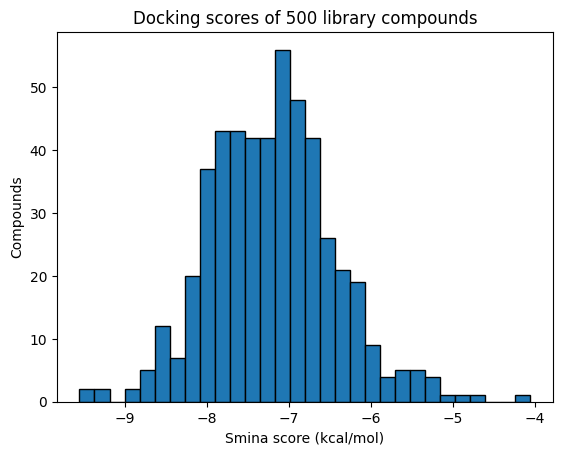

count    500.00
mean      -7.20
std        0.76
min       -9.55
25%       -7.74
50%       -7.20
75%       -6.73
max       -4.06
Name: minimizedAffinity, dtype: float64

In [ ]:
import matplotlib.pyplot as plt

plt.hist(libscores['minimizedAffinity'], bins=30, edgecolor="black")
plt.xlabel("Smina score (kcal/mol)")
plt.ylabel("Compounds")
plt.title("Docking scores of 500 library compounds")
plt.savefig("library_scores.png", dpi=200)
plt.show()

print(libscores['minimizedAffinity'].describe().round(2))

**Figure 12.** Distribution of smina docking scores for the 500 library compounds docked into the 4Z55 pocket

All 500 compounds from the sample were successfully docked and scored. The docking scores ranged from -9.55 to -4.06 kcal/mol, and show an average of -7.20 (Figure 12).

The top-ranked compound, CHEMBL3934738_8.52, was already known in ChEMBL, so it was used as a control rather than considered a new hit. The highest-scoring ZINC compounds were ZINC000020869469 (-9.42), ZINC000002104998 (-9.28), and ZINC000009009863 (-9.19). Their scores were close to the the original ligand score, 4LO, during redocking (-9.30 kcal/mol). However, the redocking used smina's default settings, and the library screening used an exhaustiveness setting of 1.

#### 4.6 Show the Top 3 Poses

 Following the sample workflow provided for this assignment, the top-scoring docking poses were visually compared to the original ligand (4LO) in PyMOL. No numerical analysis of their interactions was performed.

In [ ]:
from pymol import cmd
from IPython.display import Image

run_files = ["library_screen1.sdf", "library_screen2.sdf"]

cmd.reinitialize()
cmd.load("4Z55-receptor.pdb")      # CHANGE if named differently
cmd.load("4Z55-ligand.pdb")        # the cognate 4LO
for i, f in enumerate(run_files, start=1):
    cmd.load(f, f"virtualscreen{i}")

cmd.color("green", "4Z55-receptor")
cmd.color("grey", "4Z55-ligand")

cmd.select("pocketresidues", "byres (all within 5 of 4Z55-ligand) & polymer.protein")
cmd.show("line", "pocketresidues")
cmd.set("ray_shadow", 0)
cmd.set("cartoon_transparency", 0.8)
cmd.util.cnc()

# split each run into one object per molecule, then drop the multi-state object
for i in range(1, len(run_files) + 1):
    cmd.split_states(f"virtualscreen{i}")
    cmd.delete(f"virtualscreen{i}")

print(cmd.get_names()[:10])

['4Z55-receptor', '4Z55-ligand', 'ZINC000205694343', 'ZINC000019319363', 'ZINC000018101662', 'ZINC000032611944', 'ZINC000004344400', 'ZINC000003830893', 'ZINC000045891653', 'ZINC000013682139']

##### 4.6.1 Find Top 3 IDs

In [ ]:
top = libscores[~libscores["ID"].str.startswith("CHEMBL")] \
        .sort_values("minimizedAffinity").head(3)
print(top[["ID", "minimizedAffinity"]])

                 ID  minimizedAffinity
1  ZINC000020869469           -9.41607
2  ZINC000002104998           -9.27840
3  ZINC000009009863           -9.19413

##### 4.6.2 Top Pose 1

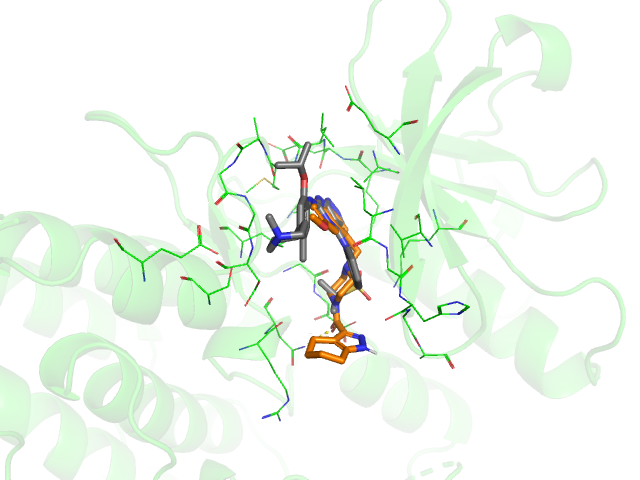

In [ ]:
cmd.hide("stick", "all and not 4Z55-ligand")
cmd.show("stick", "4Z55-ligand")
cmd.show("stick", " ZINC000020869469")
cmd.color("orange", "ZINC000020869469 and elem C")
cmd.zoom("pocketresidues", 4)
cmd.png("top_pose_1.png")
Image(filename="top_pose_1.png", unconfined=True)

**Figure 13.** Top-scoring library compound, ZINC000020869469 (-9.42 kcal/mol), docked into the 4Z55 pocket. The docked compound is shown in orange, the ligand 4LO in grey, and the receptor is in green, with residues within 5 Å of 4LO as lines.

**Observation** The compound binds in the same pocket as the original ligand (4LO), and parts of their structures overlap. However, the compound extends further down into the pocket and doesn't overlap with the isopropyl group at the top or the piperidine group on the side of 4LO.

##### 4.6.3 Top Pose 2

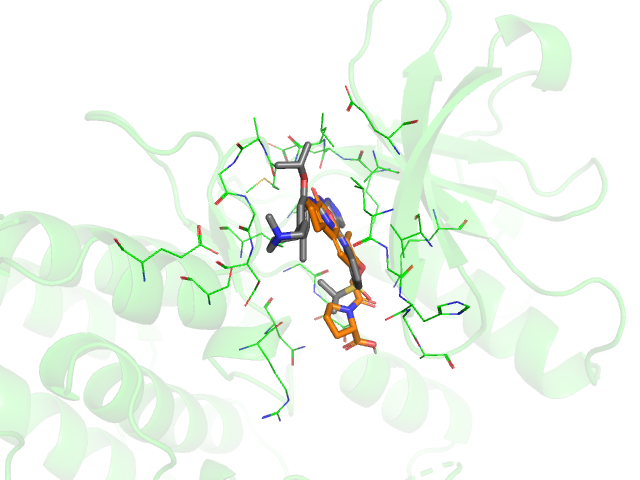

In [ ]:
cmd.hide("stick", "all and not 4Z55-ligand")
cmd.show("stick", "4Z55-ligand")
cmd.show("stick", "ZINC000002104998")
cmd.color("orange", "ZINC000002104998 and elem C")
cmd.zoom("pocketresidues", 4)
cmd.png("top_pose_2.png")
Image(filename="top_pose_2.png", unconfined=True)

**Figure 14.** Second-best library compound, ZINC000002104998 (-9.28 kcal/mol), docked into the 4Z55 pocket. The docked compound is shown in orange, the ligand 4LO in grey, and the receptor is in green, with residues within 5 Å of 4LO as lines.

 **Observation** This compound also binds in the same central pocket as the original ligand (4LO), with parts of their structures overlapping. A ring group extends further down into the pocket, but like the first compound, it doesn't overlap with the top or side groups of 4LO.

##### 4.6.4 Top Pose 3

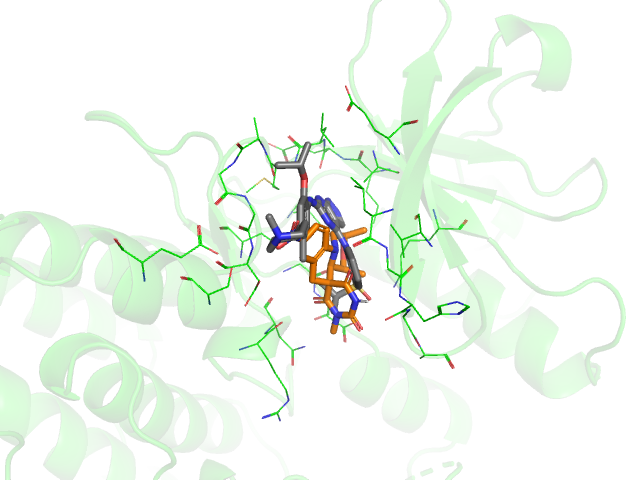

In [ ]:
cmd.hide("stick", "all and not 4Z55-ligand")
cmd.show("stick", "4Z55-ligand")
cmd.show("stick", "ZINC000009009863")
cmd.color("orange", "ZINC000009009863 and elem C")
cmd.zoom("pocketresidues", 4)
cmd.png("top_pose_3.png")
Image(filename="top_pose_3.png", unconfined=True)

**Figure 15.** Third-best library compound, ZINC000009009863 (-9.19 kcal/mol), docked into the 4Z55 pocket. The docked compound is shown in orange, the ligand 4LO in grey, and the receptor is in green, with residues within 5 Å of 4LO as lines.

 **Observation** This compound is more compact and overlaps with the lower-middle part of the original ligand (4LO). It doesn't extend as far down into the pocket as the first two compounds or overlap with the top or side groups of 4LO.

##### 4.6.5 Summary of Top 3 Poses

All of the top three scoring compounds bind in the same pocket as the original ligand (4LO), and show their central structures overlapping. Their docking scores were similar (-9.19 to -9.42 kcal/mol), however, none covers the entire area occupied by 4LO. Since the compounds were only compared visually from one angle, the results show that they bind in similar positions but can't confirm if they form the same hydrogen bonds with the hinge region. A more detailed analysis would be needed to confirm these interactions.

#### 4.7 Similarity of the library compounds to the cognate

In [ ]:
import pandas as pd
from rdkit import Chem, DataStructs
from rdkit.Chem import AllChem, PandasTools

folder = "/content/drive/MyDrive/ALK_screen/"

res = pd.concat([PandasTools.LoadSDF(folder + "library_screen1.sdf"),
                 PandasTools.LoadSDF(folder + "library_screen2.sdf")], ignore_index=True)
res['minimizedAffinity'] = pd.to_numeric(res['minimizedAffinity'], errors='coerce')
res['smiles'] = res['ROMol'].apply(lambda m: Chem.MolToSmiles(Chem.RemoveHs(m)))
libscores = res[['ID', 'smiles', 'minimizedAffinity']].sort_values('minimizedAffinity').reset_index(drop=True)
print(len(libscores), "compounds loaded")

fpgen = AllChem.GetMorganGenerator()
cognate_smiles = "Cc1cc(c(cc1C2CCN(CC2)C)OC(C)C)Nc3nc4c(c[nH]n4)c(n3)Nc5ccccc5S(=O)(=O)C(C)C"
queryfp = fpgen.GetFingerprint(Chem.MolFromSmiles(cognate_smiles))

libscores["Sim"] = [DataStructs.TanimotoSimilarity(fpgen.GetFingerprint(Chem.MolFromSmiles(s)), queryfp)
                    for s in libscores['smiles']]
libscores["is_control"] = libscores["ID"].str.startswith("CHEMBL")

zinc = libscores[~libscores["is_control"]]
top = zinc.head(10)
print(f"Positive controls in the sample: {libscores['is_control'].sum()}")
print(f"Top 10 ZINC - similarity to 4LO: {top['Sim'].min():.2f} to {top['Sim'].max():.2f}")
print(f"All ZINC - mean similarity to 4LO: {zinc['Sim'].mean():.2f}")
top[["ID", "minimizedAffinity", "Sim"]]

500 compounds loaded
Positive controls in the sample: 5
Top 10 ZINC - similarity to 4LO: 0.08 to 0.13
All ZINC - mean similarity to 4LO: 0.09

,ID,minimizedAffinity,Sim
1,ZINC000020869469,-9.41607,0.111111
2,ZINC000002104998,-9.27840,0.134228
3,ZINC000009009863,-9.19413,0.098039
4,ZINC000585150118,-8.94553,0.110390
5,ZINC000016000528,-8.85111,0.109091
6,ZINC000008790788,-8.80372,0.080247
7,ZINC000015838318,-8.73051,0.082803
8,ZINC000016042259,-8.71307,0.081761
9,ZINC000008662731,-8.68569,0.083871
10,ZINC000009938920,-8.67075,0.114650


### 5. Results and Discussion

Other docking studies give an idea of the scores reported for known ALK inhibitors. For example, lorlatinib had docking scores between -9.6 and -9.9 kcal/mol when tested against normal and mutated ALK using AutoDock Vina (Zapata Dongo et al., 2025). These scores are close to the top library compounds observed in this project (-9.2 to -9.4 kcal/mol). However, these scores can’t be directly compared because different studies use different software, protein structures, and docking settings. For example, Zapata Dongo et al. (2025) reported a score of -9.7 kcal/mol for lorlatinib with normal ALK, while an earlier study reported -8.9 kcal/mol (Balasundaram & Doss, 2023).

Known active compounds were also available in ChEMBL (CHEMBL4247) for comparison. After filtering, the dataset contained 890 active compounds with pChEMBL values > 8 and 233 inactive compounds with activity > 10 µM. From these, 50 active and 100 inactive compounds were randomly selected and docked using the same settings as the library screening (Section 4). This was useful for checking the docking results because their activity against ALK had already been tested experimentally.

The 500 compounds contained 5 ChEMBL positive controls (known actives) and 495 ZINC compounds. The docking scores ranged from -9.55 to -4.06 kcal/mol, with an average of -7.20 kcal/mol (Figure 12). The top-scoring compound was a known active from ChEMBL (CHEMBL3934738, pChEMBL 8.52), with a score of -9.55 kcal/mol. The three top-scoring ZINC compounds had scores of -9.42, -9.28, and -9.19 kcal/mol. These were close to the original ligand, 4LO (-9.3 kcal/mol). However, 4LO was redocked with the default exhaustiveness of 8, while the screen used an exhaustiveness of 1, so the two scores are not directly comparable.

The top-scoring ZINC compounds had low Tanimoto similarity scores to 4LO (0.08–0.13), which were close to the library average of 0.09, meaning that they are structurally dissimilar to the known ligand. This means their high docking scores are probably not due to resemblance to 4LO.

There were a few limitations to this screening that are worth mentioning. First, docking was done using the fastest settings (exhaustiveness of 1 and one pose per compound), and only 500 of the 13,291 compounds were tested, so a large portion of the library wasn’t screened. There were also differences in how the compounds were prepared. The ChEMBL compounds were neutral, while some ZINC compounds may have differed in protonation state. These differences could have affected the docking scores and made it harder to compare the two groups fairly (Irwin, 2008).

Lastly, the three top-scoring compounds were only compared visually with the original ligand (4LO). Their hydrogen bonds and interactions with the hinge region were not analyzed in detail. More analysis and experimental testing would be needed to confirm if these compounds actually inhibit ALK.



### References

[1] Balasundaram, A., & Doss, G. P. C. (2024). A computational examination of the therapeutic advantages of fourth-generation ALK inhibitors TPX-0131 and repotrectinib over third-generation lorlatinib for NSCLC with alk F1174C/L/V mutations. Frontiers in Molecular Biosciences, 10, 1306046. PubMed. https://doi.org/10.3389/fmolb.2023.1306046

[2] Data Bank, R. P. (2024). RCSB PDB - 9gbe: Structure of human anaplastic lymphoma kinase (ALK) harboring the G1202R/L1196M compound mutation in complex with NVL-655. Rcsb.Org. https://www.rcsb.org/structure/9GBE

[3] Data, P (2016). RCSB PDB - 5a9u: Structure of C1156Y mutant human anaplastic lymphoma kinase in complex with PF-06463922 ((10R)-7-amino-12-fluoro-2,10,16-trimethyl- 15-oxo-10,15,16,17-tetrahydro-2H-8,4-(metheno)pyrazolo(4,3-H)(2,5,11) benzoxadiazacyclotetradecine-3-carbonitrile). Rcsb.Org. https://www.rcsb.org/structure/5A9U


[4] Dedoni, S., Scherma, M., Camoglio, C., Siddi, C., Fratta, W., & Fadda, P. (2023). Anaplastic Lymphoma Kinase Receptor: Possible Involvement in Anorexia Nervosa. Nutrients, 15(9), 2205. https://doi.org/10.3390/nu15092205

[5] Irwin, J. J. (2008). Community benchmarks for virtual screening. Journal of Computer-Aided Molecular Design, 22(3–4), 193–199. PubMed. https://doi.org/10.1007/s10822-008-9189-4

[6] Katic, L., & Priscan, A. (2023). Multifaceted roles of ALK family receptors and augmentor ligands in health and disease: A comprehensive review. Biomolecules, 13(10), 1490. https://doi.org/10.3390/biom13101490

[7] Koes, D. R., Baumgartner, M. P., & Camacho, C. J. (2013). Lessons learned in empirical scoring with Smina from the CSAR 2011 benchmarking exercise. Journal of Chemical Information and Modeling, 53(8), 1893–1904. https://doi.org/10.1021/ci300604z

[8] Lee, C. C., & Spraggon, G. (2016). Anaplastic lymphoma kinase catalytic domain complexed with pyrazolopyrimidine derivative of LDK378 (PDB ID 4Z55)

[9] Luca, M., Tardy, S., Zambon, A., Alexandre, O., Bisson, W. H., Ceccon, M., Michela, V., D’Attoma, J., Pannilunghi, S., Vece, V., Bertho, J., Goekjian, P., Scapozza, L., & Gambacorti-Passerini, C. (2022). Discovery of novel α‑carboline inhibitors of the anaplastic lymphoma kinase. ACS Omega, 7(20), 17083–17097. https://doi.org/10.1021/acsomega.2c00507

[10] Michellys, P.-Y., Bei, C., Tao, J., Jin, Y., Lu, W., Marsilje, T. H., Pei, W., Uno, T., Zhu, X., Wu, B., Ngoc, N. T., Bursulaya, B., Lee, C., Li, N., Kim, S., Tuntland, T., Liu, B., Sun, F., Steffy, A., & Hood, T. (2016). Design and synthesis of novel selective anaplastic lymphoma kinase inhibitors. Bioorganic & Medicinal Chemistry Letters, 26(3), 1090–1096. https://doi.org/10.1016/j.bmcl.2015.11.049

[11] RCSB Protein Data Bank. (n.d.). 4LO [Chemical component]. https://www.rcsb.org/ligand/4LO

[12] Trott, O., & Olson, A. J. (2009). AutoDock Vina: Improving the speed and accuracy of docking with a new scoring function, efficient optimization, and multithreading. Journal of Computational Chemistry, 31(2). https://doi.org/10.1002/jcc.21334

[13] Umapathy et al. (2019). Targeting anaplastic lymphoma kinase in neuroblastoma. APMIS. https://doi.org/10.1111/apm.12940

[14] UniProt Consortium. (n.d.). ALK_HUMAN (Q9UM73). UniProt. https://www.uniprot.org/uniprotkb/Q9UM73/entry

[15] Yoda, S., Lin, J. J., Lawrence, M. S., Burke, B. J., Friboulet, L., Langenbucher, A., Dardaei, L., Prutisto-Chang, K., Dagogo-Jack, I., Timofeevski, S., Hubbeling, H., Gainor, J. F., Ferris, L. A., Riley, A. K., Kattermann, K. E., Timonina, D., Heist, R. S., Iafrate, A. J., Benes, C. H., … Shaw, A. T. (2018). Sequential ALK inhibitors can select for lorlatinib-resistant compound ALK mutations in ALK-Positive lung cancer. Cancer Discovery, 8(6), 714–729. https://doi.org/10.1158/2159-8290.CD-17-1256

[16] Zapata Dongo, R. J., Poterico, J. A., Fontana, D., Mologni, L., Alvarez-Chacon, C., Rojas-Armas, J., & Calla, J. (2025). An in silico evaluation of lorlatinib as a potential therapy for novel amino acid substitutions in the tyrosine kinase domain of the ALK protein associated with cancer. Frontiers in Pharmacology, 16, Article 1605314. https://doi.org/10.3389/fphar.2025.1605314